* Project of the Job Analysis -Rahul S M

In [51]:
#Importing the dependencies 
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import os

In [2]:
#Importing the CSV File
df=pd.read_csv(r"C:\Users\rahul\Downloads\job_market_intelligence_dataset.csv")

In [3]:
#1st 3 rows
df.tail()

,job_id,job_title,company,location,experience_years,employment_type,salary_lpa,skills,remote
15,16,Data Scientist,FinTechX,Mumbai,1,Full-time,9.0,Python;SQL;Machine Learning;Pandas,Yes
16,17,Business Analyst,DataWorks,Pune,2,Full-time,7.5,SQL;Excel;Tableau;Power BI,No
17,18,Data Analyst,TechNova,Bengaluru,2,Full-time,8.0,Python;SQL;Power BI;Tableau,Yes
18,19,ML Engineer,CloudData,Hyderabad,3,Full-time,14.0,Python;TensorFlow;Scikit-learn;AWS,Yes
19,20,Data Scientist,AnalyticsPro,Delhi,5,Full-time,19.0,Python;SQL;Machine Learning;AWS;Docker,Yes


In [4]:
#Shape of the Dataset
df.shape

(20, 9)

In [5]:
#Datatype of the each Row
df.dtypes

job_id                int64
job_title               str
company                 str
location                str
experience_years      int64
employment_type         str
salary_lpa          float64
skills                  str
remote                  str
dtype: object

In [6]:
#Finding the nul values in our dataset'set 
df.isnull().sum() #I.e:No null values

job_id              0
job_title           0
company             0
location            0
experience_years    0
employment_type     0
salary_lpa          0
skills              0
remote              0
dtype: int64

In [7]:
print(df.duplicated().sum())


0


* Data Cleaning

In [8]:
#Removing duplicates values from the dataset
df.drop_duplicates()

,job_id,job_title,company,location,experience_years,employment_type,salary_lpa,skills,remote
0,1,Data Scientist,TechNova,Pune,1,Full-time,8.5,Python;SQL;Machine Learning;Pandas,Yes
1,2,Data Analyst,FinTechX,Mumbai,0,Full-time,5.5,Python;SQL;Excel;Power BI,No
2,3,ML Engineer,AI Labs,Bengaluru,2,Full-time,12.0,Python;TensorFlow;Machine Learning;Docker,Yes
3,4,Data Engineer,CloudData,Hyderabad,3,Full-time,11.5,Python;SQL;AWS;Spark,Yes
4,5,Data Analyst,DataWorks,Pune,1,Full-time,6.0,SQL;Excel;Power BI;Tableau,No
5,6,Data Scientist,AI Labs,Bengaluru,3,Full-time,15.0,Python;SQL;Machine Learning;Scikit-learn,Yes
6,7,Business Analyst,FinTechX,Mumbai,2,Full-time,7.0,SQL;Excel;Power BI,No
7,8,ML Engineer,TechNova,Pune,1,Full-time,10.0,Python;Machine Learning;PyTorch;Docker,Yes
8,9,Data Scientist,CloudData,Hyderabad,4,Full-time,17.5,Python;SQL;TensorFlow;AWS,Yes
9,10,Data Analyst,AnalyticsPro,Delhi,1,Full-time,6.5,Python;SQL;Excel;Tableau,No


In [9]:
#Converting the salary into numeric safely
df['salary_lpa']=pd.to_numeric(df['salary_lpa'],errors='coerce')

In [10]:
df.head(3)

,job_id,job_title,company,location,experience_years,employment_type,salary_lpa,skills,remote
0,1,Data Scientist,TechNova,Pune,1,Full-time,8.5,Python;SQL;Machine Learning;Pandas,Yes
1,2,Data Analyst,FinTechX,Mumbai,0,Full-time,5.5,Python;SQL;Excel;Power BI,No
2,3,ML Engineer,AI Labs,Bengaluru,2,Full-time,12.0,Python;TensorFlow;Machine Learning;Docker,Yes


In [11]:
#Finding missing values of salary to median
df['salary_lpa']=df['salary_lpa'].fillna(df['salary_lpa'].median)

In [12]:
#-----------mean------------
#df['salary_lpa']=df['salary_lpa'].fillna(df['salary_lpa'].mean)

In [13]:
#Converting enperince into numeric 
df['experience_years']=pd.to_numeric(df['experience_years'],errors='coerce')


* descriptive Stastics

In [14]:
#Avg salary by role
salary_by_role=(
    df.groupby('job_title')['salary_lpa'].mean().sort_values(ascending=False)
)
print(salary_by_role)

job_title
ML Engineer         13.500000
Data Scientist      13.333333
Data Engineer       12.666667
Business Analyst     7.250000
Data Analyst         6.200000
Name: salary_lpa, dtype: float64


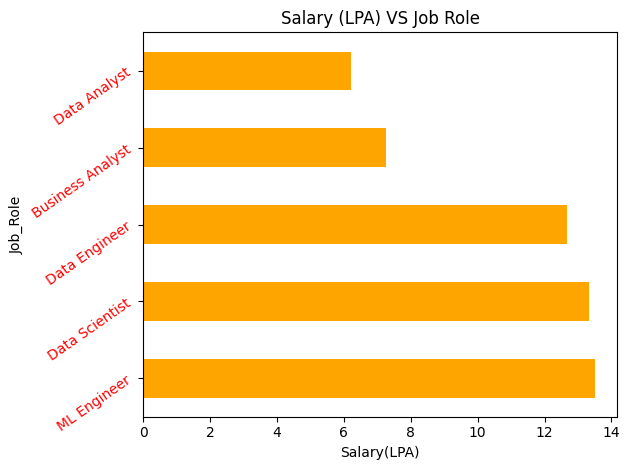

In [15]:
# Visualization
plt.Figure(figsize=(10,6))
salary_by_role.plot(kind='barh',color='orange')
plt.title("Salary (LPA) VS Job Role")
plt.xlabel('Salary(LPA)')
plt.ylabel('Job_Role')
plt.yticks(rotation=35,color='Red')
plt.tight_layout()
plt.show()

In [16]:
#Salary vs location
salary_location=(
    df.groupby('location')['salary_lpa'].mean()
    .sort_values(ascending=False)    
)

* Visualization

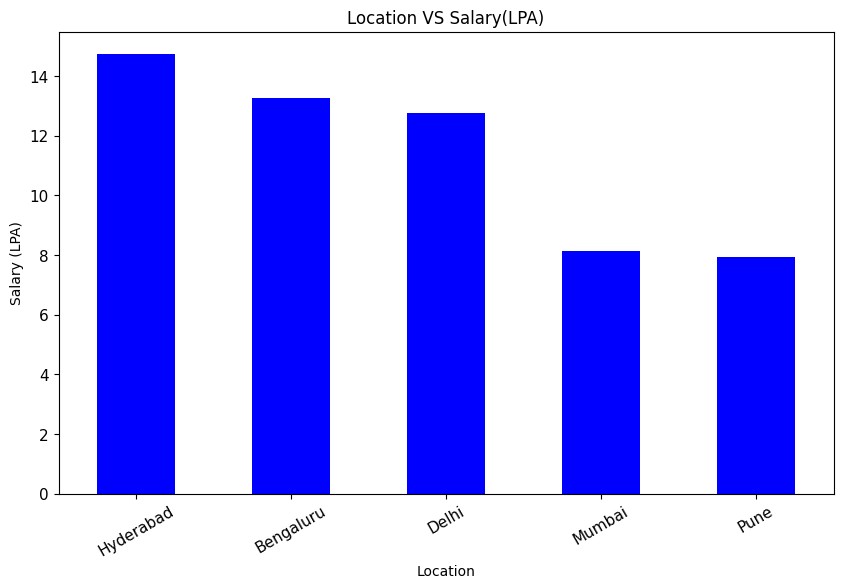

In [17]:
plt.figure(figsize=(10,6))
plt.tight_layout()
salary_location.plot(kind='bar',color='blue',fontsize=11)
plt.xlabel('Location')
plt.ylabel('Salary (LPA)')
plt.title('Location VS Salary(LPA)')
plt.xticks(rotation=30)
plt.show()

In [18]:
#Salary vs location
salary_location=(
    df.groupby('experience_years')['salary_lpa'].mean()
    .sort_values(ascending=False)    
)

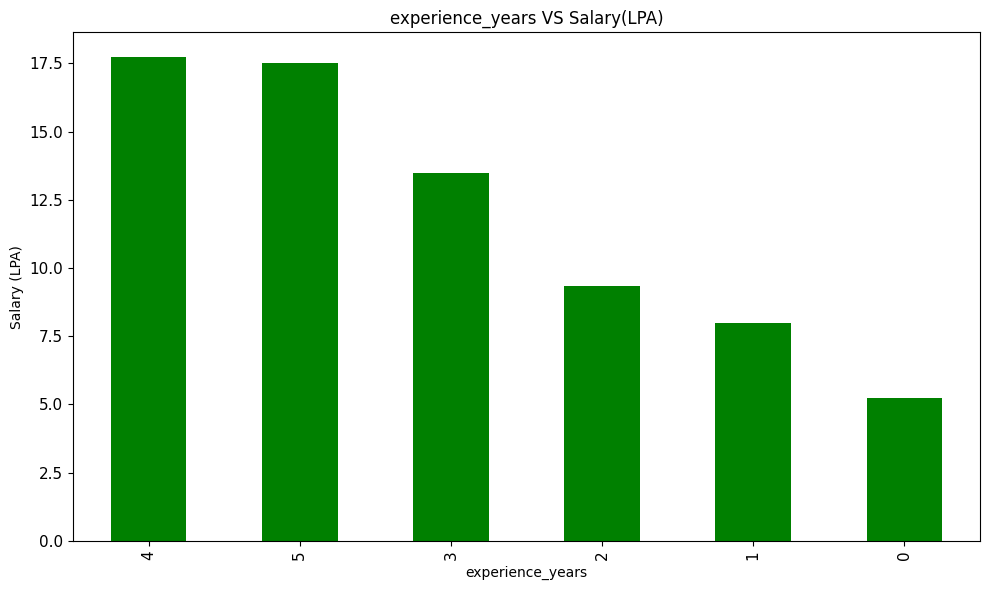

In [19]:
plt.figure(figsize=(10,6))
salary_location.plot(kind='bar',color='green',fontsize=11)
plt.xlabel('experience_years')
plt.ylabel('Salary (LPA)')
plt.title('experience_years VS Salary(LPA)')
plt.tight_layout()
plt.show()

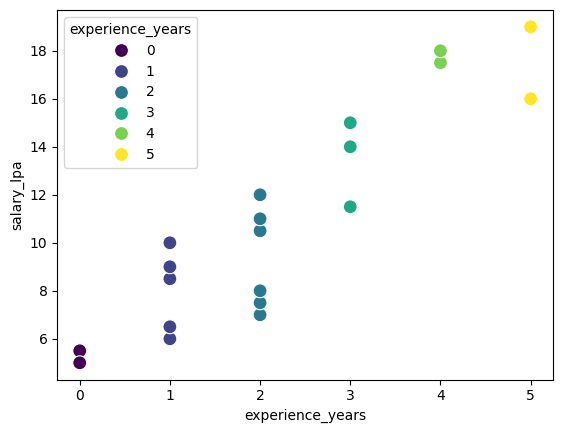

In [20]:
#Scatterplot for the experience_years VS Salary(LPA)
plt.Figure(figsize=(10,10))
sns.scatterplot(
    data=df,
    x='experience_years',
    y='salary_lpa',
    s=100,
    hue='experience_years',
    palette='viridis'
)

plt.show()

<Axes: xlabel='salary_lpa', ylabel='Count'>

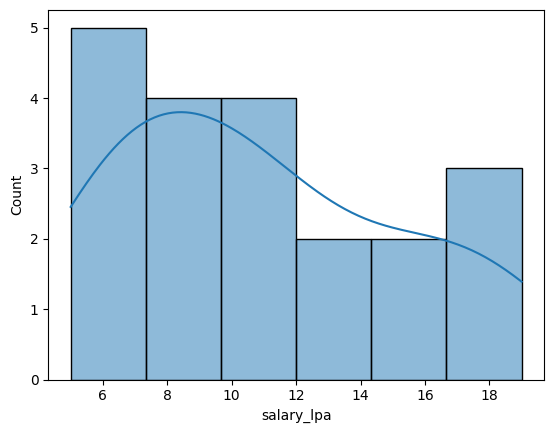

In [21]:
#salary distribution by number's of jobs
sns.histplot(df['salary_lpa'],
             kde=True
             )

In [22]:
df.head(2
        )

,job_id,job_title,company,location,experience_years,employment_type,salary_lpa,skills,remote
0,1,Data Scientist,TechNova,Pune,1,Full-time,8.5,Python;SQL;Machine Learning;Pandas,Yes
1,2,Data Analyst,FinTechX,Mumbai,0,Full-time,5.5,Python;SQL;Excel;Power BI,No


In [23]:
#Remote Job Analysis
df['remote'].value_counts()

remote
Yes    13
No      7
Name: count, dtype: int64

In [24]:
#Employment types
print(df['employment_type'].value_counts())

employment_type
Full-time    20
Name: count, dtype: int64


In [30]:
df.head(3)

,job_id,job_title,company,location,experience_years,employment_type,salary_lpa,skills,remote
0,1,Data Scientist,TechNova,Pune,1,Full-time,8.5,Python;SQL;Machine Learning;Pandas,Yes
1,2,Data Analyst,FinTechX,Mumbai,0,Full-time,5.5,Python;SQL;Excel;Power BI,No
2,3,ML Engineer,AI Labs,Bengaluru,2,Full-time,12.0,Python;TensorFlow;Machine Learning;Docker,Yes


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt   # for visualization

# Step 1: Create an empty list to store all skills
skills = []

# Step 2: Loop through each row in the 'skills' column of the DataFrame
for skill_list in df['skills']:
    # Split the string into individual skills using ';' as separator
    skill_list = skill_list.split(';')
    
    # Step 3: Loop through each skill in the split list
    for skill in skill_list:
        # Clean extra spaces and add to the main skills list
        skills.append(skill.strip())

# Step 4: Convert the list into a pandas Series
skill_series = pd.Series(skills)

# Step 5: Count frequency of each skill
skill_counts = skill_series.value_counts()

# Step 6: Print results
print("\n========== MOST DEMANDED SKILLS ==========\n")
print(skill_counts)


========== MOST DEMANDED SKILLS ==========

Python              16
SQL                 16
Machine Learning     7
AWS                  7
Excel                6
Power BI             6
Docker               5
TensorFlow           4
Tableau              4
Pandas               3
Spark                3
Scikit-learn         2
PyTorch              2
Name: count, dtype: int64


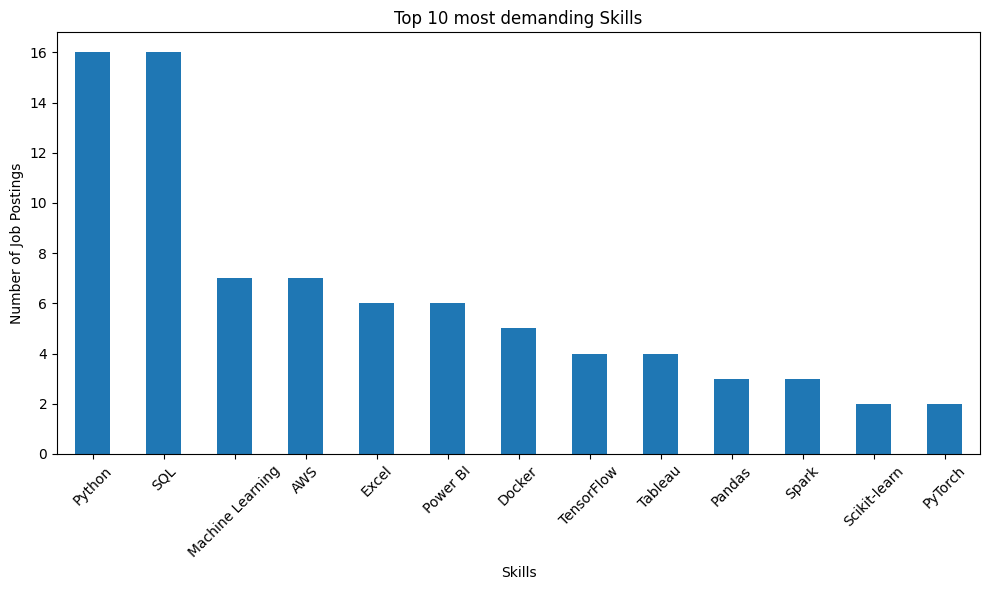

In [33]:
#Plotting the graph of number of posting and skills
plt.figure(figsize=(10,6))
skill_counts.plot(kind='bar'),
plt.title("Top 10 most demanding Skills")

plt.xlabel("Skills")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.show()

In [37]:
#Percentage of the Skills in Our Dataset
skills_percentage=(
  (skill_counts/len(df))*100  
)
print("The percentage of the skills are",skills_percentage .round(2).head(5)  )

The percentage of the skills are Python              80.0
SQL                 80.0
Machine Learning    35.0
AWS                 35.0
Excel               30.0
Name: count, dtype: float64


In [40]:
#Job by location
job_location=df['location'].value_counts()
print("Job location",job_location)

Job location location
Pune         6
Mumbai       4
Bengaluru    4
Hyderabad    4
Delhi        2
Name: count, dtype: int64


In [46]:
#Experiecnce Level
def experience_level(years):
    
    if years <1:
        return 'Beginers'
    
    elif years >1 :
        return 'Mid_level'
    
    else:
        return 'Senior'

df['experience_level']=(
    df['experience_years'].apply(experience_level)
    
)

print('\n==========Experience Level===========')

print(df[
    [
    'job_title',
    'experience_years',
    'experience_level',
    'salary_lpa'   
    ]
])


==========Experience Level===========
           job_title  experience_years experience_level  salary_lpa
0     Data Scientist                 1           Senior         8.5
1       Data Analyst                 0         Beginers         5.5
2        ML Engineer                 2        Mid_level        12.0
3      Data Engineer                 3        Mid_level        11.5
4       Data Analyst                 1           Senior         6.0
5     Data Scientist                 3        Mid_level        15.0
6   Business Analyst                 2        Mid_level         7.0
7        ML Engineer                 1           Senior        10.0
8     Data Scientist                 4        Mid_level        17.5
9       Data Analyst                 1           Senior         6.5
10     Data Engineer                 2        Mid_level        10.5
11    Data Scientist                 2        Mid_level        11.0
12       ML Engineer                 4        Mid_level        18.0
13      D

In [49]:
#Salary by exp level
salary_by_exp=(
    df.groupby(experience_level)['salary_lpa'].mean().sort_values(ascending=False)
)
print(salary_by_exp)

Mid_level    11.305556
Beginers      8.500000
Senior        5.500000
Name: salary_lpa, dtype: float64


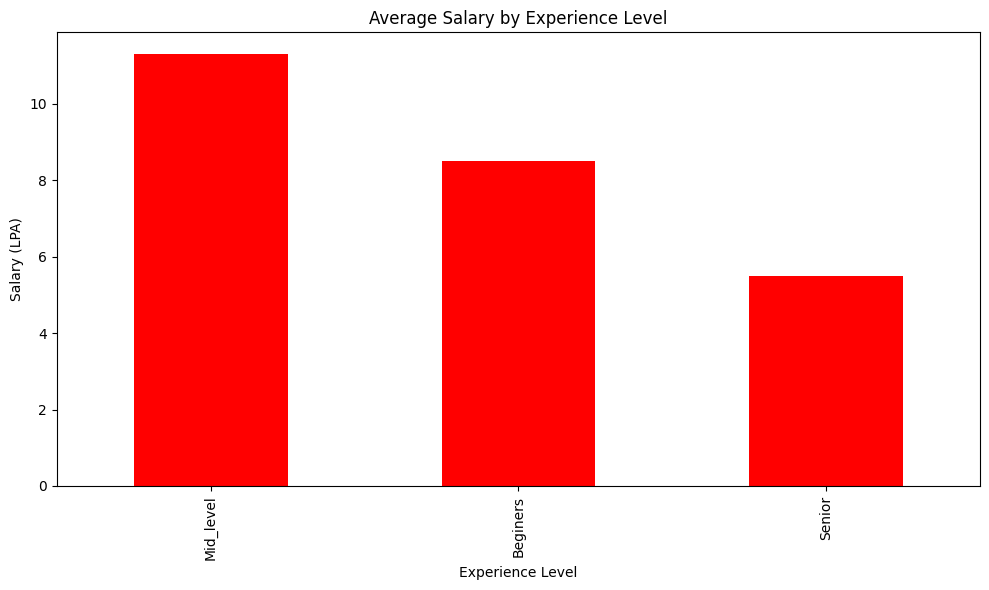

In [50]:
plt.figure(figsize=(10,6))
salary_by_exp.plot(kind='bar',color='red')

plt.title("Average Salary by Experience Level")

plt.xlabel("Experience Level")

plt.ylabel("Salary (LPA)")

plt.tight_layout()

plt.show()

In [52]:
#Save clean Data
os.makedirs("../outputs", exist_ok=True)

df.to_csv(
    "../outputs/cleaned_job_data.csv",
    index=False
)

print("\nCleaned dataset saved successfully.")



Cleaned dataset saved successfully.


In [53]:
#Final summary 
print("\n=========Job Market Analysis==========\n")
print("\n Total number of jobs:",len(df))

print(
    "Minimum salary:",
    df['salary_lpa'].min(),
    "LPA"
)

print(
    "Most Common Job Role",
    df['job_title'].mode()[0]
)

print(
    "Most Demanded Skills:",
    skill_counts.index[0]
)


=========Job Market Analysis==========


 Total number of jobs: 20
Minimum salary: 5.0 LPA
Most Common Job Role Data Scientist
Most Demanded Skills: Python
